In [17]:
import numpy as np
from scipy import linalg as la

# Given matrix M
M = np.array([
    [12, 8, 8],
    [22, 12, 14],
    [26, 20, 18]
])

# Perform SVD decomposition of M
U, S, V = la.svd(M)

# Truncate the matrices to get a low-rank one.
r = 2
Ut = U[:,0:r]
Vt = V[:,0:r]
St = S[0:r]

# Constructing low-rank matrix Mt.
Mt = Ut.dot(np.diag(St)).dot(Vt.T)

print("Size of Mt:", Mt.shape)
print("Rank:", np.linalg.matrix_rank(Mt))
print("Mt:", Mt)
print("Error:", la.norm(Mt - M, "fro")/la.norm(M, "fro"))
print("M - Mt = ", M - Mt)   

print(np.linalg.matrix_rank(M))

Size of Mt: (3, 3)
Rank: 2
Mt: [[ 11.99440983   8.71326381  -7.22586788]
 [ 21.89416455  13.23696904 -13.01645917]
 [ 26.08347478  21.61608619 -15.88701235]]
Error: 0.9204571609204705
M - Mt =  [[ 5.59016752e-03 -7.13263807e-01  1.52258679e+01]
 [ 1.05835449e-01 -1.23696904e+00  2.70164592e+01]
 [-8.34747790e-02 -1.61608619e+00  3.38870123e+01]]
2


In [25]:
import numpy as np
from scipy import linalg as la
from sklearn.linear_model import LinearRegression

# Given matrix M
M = np.array([[12, 8, 8], [22, 12, 14], [26, 20, 18]])

# U_0
U_0 = np.array([[1, 0], [0, 1], [1, 1]])

# Linear Regression model for solving least squares problems
lin_reg = LinearRegression(fit_intercept=False)

# This function solves the least squares subproblem for V given U
def LS4V(U, y, n):
    X = np.kron(np.identity(n), U)
    lin_reg.fit(X, y)
    return np.reshape(lin_reg.coef_.copy(), (n, -1))

# This function solves the least squares subproblem for U given V
def LS4U(V, y, m):
    X = np.kron(V, np.identity(m))
    lin_reg.fit(X, y)
    return np.reshape(lin_reg.coef_.copy(), (-1, m)).T

# The AMA
def AMA(U0, m, n, M, maxit=11):
    Ut = U0
    y = np.matrix.flatten(M.T)
    for t in range(maxit):
        Vt = LS4V(Ut, y, n)
        Ut = LS4U(Vt, y, m)
        fx =  0.5*np.linalg.norm(Ut.dot(Vt.T) - M, ord='fro')
        print("Iteration: {0:2d}".format(t), "-- Objective Value: {0:5.4e}".format(fx))
    return Ut, Vt, fx

# Running the AMA
m, n, r = 3, 3, 2
U_star, V_star, fx = AMA(U_0, m, n, M)

# Calculate the relative error
Mt = U_star.dot(V_star.T)
error = la.norm(Mt - M, 'fro') / la.norm(M, 'fro')

# Results
Mt, error

Iteration:  0 -- Objective Value: 1.5851e-14
Iteration:  1 -- Objective Value: 1.6407e-14
Iteration:  2 -- Objective Value: 1.0224e-14
Iteration:  3 -- Objective Value: 9.8604e-15
Iteration:  4 -- Objective Value: 7.0076e-15
Iteration:  5 -- Objective Value: 1.0887e-14
Iteration:  6 -- Objective Value: 8.5191e-15
Iteration:  7 -- Objective Value: 1.6353e-14
Iteration:  8 -- Objective Value: 1.2347e-14
Iteration:  9 -- Objective Value: 1.3114e-14
Iteration: 10 -- Objective Value: 1.6945e-14


(array([[12.,  8.,  8.],
        [22., 12., 14.],
        [26., 20., 18.]]),
 6.783574731503468e-16)

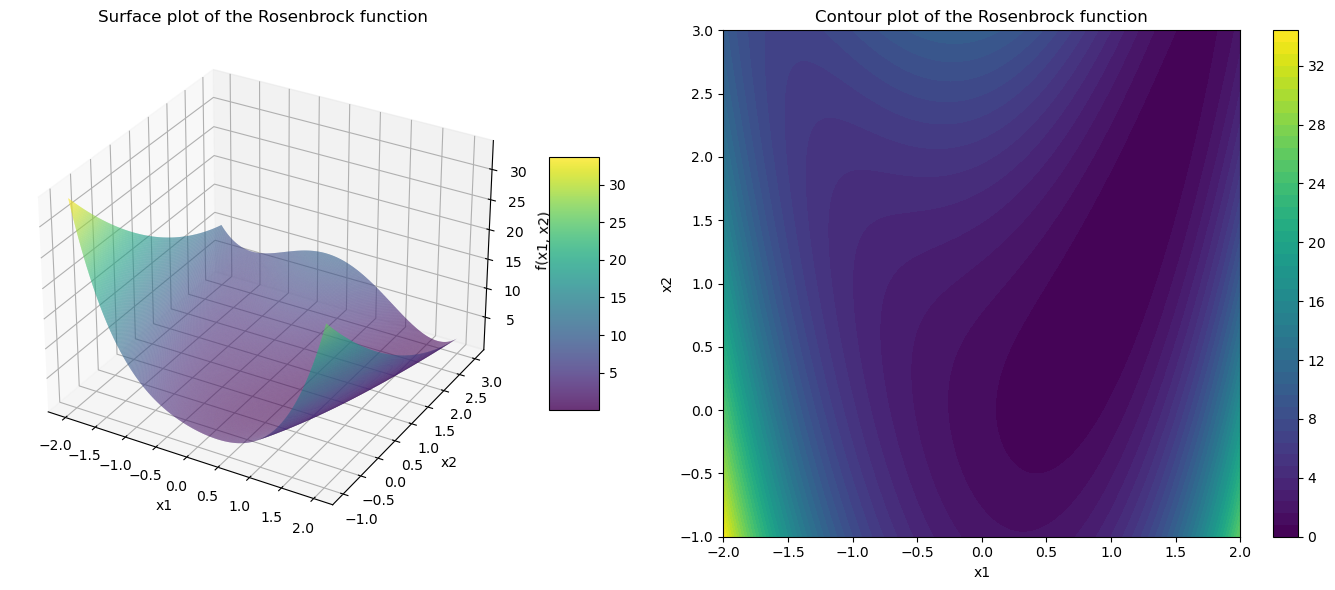

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Rosenbrock function
def rosenbrock(x1, x2, a=1, b=1):
    return (x1 - a)**2 + b*(x2 - x1**2)**2

# Generate grids of values for x1 and x2
x = np.linspace(-2, 2, 400)
y = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x, y)
Z = rosenbrock(X, Y)

# Plot the surface
fig = plt.figure(figsize=(14, 6))

# Surface plot
ax = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, cmap=cm.viridis, edgecolor='none', alpha=0.8)
ax.set_title('Surface plot of the Rosenbrock function')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('f(x1, x2)')
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)

# Contour plot
ax = fig.add_subplot(1, 2, 2)
contour = ax.contourf(X, Y, Z, 50, cmap=cm.viridis)
ax.set_title('Contour plot of the Rosenbrock function')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
fig.colorbar(contour, ax=ax)

plt.tight_layout()
plt.show()

In [30]:
import numpy as np
from numpy import linalg as la

# Rosenbrock function and its gradient
f_rosen = lambda x1, x2: (x1 - 1)**2 + (x2 - x1**2)**2
df_rosen = lambda x1, x2: (2*(x1 - 1) - 4*x1*(x2 - x1**2), 2*(x2 - x1**2))

def rosen_gd_backsearch(f_rosen, df_rosen, x0, y0, eta_start=1.0, maxit=1000, tol=1e-5):
    x, y = x0, y0
    xc, yc, fc, dc = [], [], [], []
    eta = eta_start # Start with a reasonably large eta
    for t in range(maxit):
        fval = f_rosen(x, y)
        dx, dy = df_rosen(x, y)
        res = la.norm([dx, dy])
        xc.append(x)
        yc.append(y)
        fc.append(fval)
        dc.append(res)
        print("Iter: {0:4d}, Error: {0:6.3e}, F(x): {0:6.3e}, Eta: {1}".format(t, res, fval, eta))
        
        # Update step with backsearch for eta
        eta_temp = eta
        while True:
            x_new = x - eta_temp * dx
            y_new = y - eta_temp * dy
            if f_rosen(x_new, y_new) < fval:
                x, y = x_new, y_new
                break
            else:
                eta_temp /= 2
        eta = eta_temp
        if res <= tol:
            print("Converged!")
            break
    return x, y, f_rosen(x, y), xc, yc, fc, dc

# Set Parameters
x0, y0 = 0, 0
eta_start = 0.1
maxit = 1000
tol = 1e-8

# Run the gradient descent
x_opt_bs, y_opt_bs, f_opt_bs, xc_bs, yc_bs, fc_bs, dc_bs = rosen_gd_backsearch(f_rosen, df_rosen, x0, y0, eta_start, maxit, tol)

print(f"Solution with backsearch: x_opt = {x_opt_bs:3.6f}, y_opt = {y_opt_bs:3.6f}")
print(f"Optimal value: {f_opt_bs:3.6f}")


Iter:    0, Error: 0.000e+00, F(x): 0.000e+00, Eta: 2.0
Iter:    1, Error: 1.000e+00, F(x): 1.000e+00, Eta: 1.570039489949218
Iter:    2, Error: 2.000e+00, F(x): 2.000e+00, Eta: 1.1413472141363068
Iter:    3, Error: 3.000e+00, F(x): 3.000e+00, Eta: 0.8045619187153402
Iter:    4, Error: 4.000e+00, F(x): 4.000e+00, Eta: 0.6262839728158047
Iter:    5, Error: 5.000e+00, F(x): 5.000e+00, Eta: 0.5454741034965901
Iter:    6, Error: 6.000e+00, F(x): 6.000e+00, Eta: 0.4959608611771821
Iter:    7, Error: 7.000e+00, F(x): 7.000e+00, Eta: 0.45622571723272964
Iter:    8, Error: 8.000e+00, F(x): 8.000e+00, Eta: 0.4217665195457907
Iter:    9, Error: 9.000e+00, F(x): 9.000e+00, Eta: 0.391331480954212
Iter:   10, Error: 1.000e+01, F(x): 1.000e+01, Eta: 0.3642284348688324
Iter:   11, Error: 1.100e+01, F(x): 1.100e+01, Eta: 0.3399386370277283
Iter:   12, Error: 1.200e+01, F(x): 1.200e+01, Eta: 0.31804859559377685
Iter:   13, Error: 1.300e+01, F(x): 1.300e+01, Eta: 0.29822298976493083
Iter:   14, Error: 1

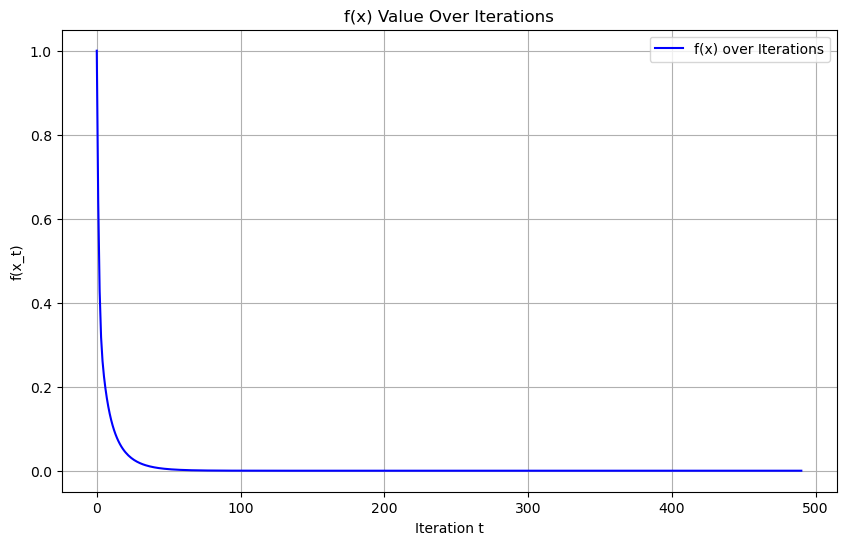

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(fc_bs, label='f(x) over Iterations', color='blue')
plt.xlabel('Iteration t')
plt.ylabel('f(x_t)')
plt.title('f(x) Value Over Iterations')
#plt.yscale('log') # Log scale if needed
plt.legend()
plt.grid(True)
plt.show()

In [38]:
import numpy as np

def grad_fx_eval(beta, X, y):
    n = X.shape[0]
    sigma = lambda tau: np.maximum(0, tau)
    sigma_prime = lambda tau: (tau >= 0).astype(float)
    
    residuals = sigma(X.dot(beta)) - y
    gradients = np.dot(X.T, residuals * sigma_prime(X.dot(beta))) * 2 / n
    
    return gradients

# Generate Data
n, d = 100, 10 
sig = 0.05
np.random.seed(42)
from sklearn import preprocessing as pp
X_data = np.random.randn(n, d)
X_data = pp.normalize(X_data, axis=0)
beta_truth = np.random.randn(d + 1)
X = np.concatenate((np.ones((n, 1)), X_data), axis=1)
y = np.maximum(0, X.dot(beta_truth)) + sig * np.random.randn(n)

# Compute the gradient at beta_truth
grad = grad_fx_eval(beta_truth, X, y)
print("Gradient at beta_truth:", grad)

Gradient at beta_truth: [-0.01060473  0.0002428   0.00098994  0.00018529  0.00144895 -0.00036253
 -0.00131494 -0.00078744 -0.00046312 -0.00032396  0.00156542]


In [44]:
import numpy as np
from numpy import linalg as la
from sklearn import preprocessing as pp
import matplotlib.pyplot as plt

# Objective function
def obj_func(beta, X, y):
    n = X.shape[0]
    residuals = np.maximum(0, X.dot(beta)) - y
    return np.sum(residuals ** 2) / n

# Gradient Descent Algorithm
def GDA(obj_fun, obj_grad, x0, X, y, max_iter=int(1e4), tol=1e-4):
    
    eta = 0.1  # Initial learning rate
    x_cur = x0
    hist = []
    
    for t in range(max_iter):
        grad_fx = obj_grad(x_cur, X, y)
        if t == 0:
            nrm_grad0 = la.norm(grad_fx)
        fx_val = obj_fun(x_cur, X, y)
        
        # Backsearch learning rate
        eta_adjusted = eta
        while True:
            x_next = x_cur - eta_adjusted * grad_fx
            if obj_fun(x_next, X, y) < fx_val:
                break
            eta_adjusted /= 2
        
        x_cur = x_next
        fx_val = obj_fun(x_cur, X, y)
        rel_err = la.norm(grad_fx) / np.maximum(1, nrm_grad0)
        
        # Store Results
        hist.append([t, fx_val, rel_err, eta_adjusted])
        if t % 100 == 0:
            print(f"Iter={t:4d}, F(x)={fx_val:^3.4e}, Error={rel_err:^3.4e}, Learning Rate={eta_adjusted:^3.4e}")
        
        if rel_err <= tol:
            print("Converged!")
            break
    
    return x_cur, fx_val, hist


# Initial guess for beta
beta_init = np.zeros(d + 1)

# Run Gradient Descent
beta_opt, final_val, history = GDA(obj_func, grad_fx_eval, beta_init, X, y)

print("beta_opt:", beta_opt)
print("beta_truth:", beta_truth)

Iter=   0, F(x)=1.3576e+00, Error=1.0000e+00, Learning Rate=1.0000e-01
Iter= 100, F(x)=4.1236e-02, Error=1.4299e-02, Learning Rate=1.0000e-01
Iter= 200, F(x)=2.7992e-02, Error=1.1388e-02, Learning Rate=1.0000e-01
Iter= 300, F(x)=1.9530e-02, Error=9.1405e-03, Learning Rate=1.0000e-01
Iter= 400, F(x)=1.4038e-02, Error=7.3947e-03, Learning Rate=1.0000e-01
Iter= 500, F(x)=1.0417e-02, Error=6.0287e-03, Learning Rate=1.0000e-01
Iter= 600, F(x)=7.9926e-03, Error=4.9518e-03, Learning Rate=1.0000e-01
Iter= 700, F(x)=6.3460e-03, Error=4.0962e-03, Learning Rate=1.0000e-01
Iter= 800, F(x)=5.2120e-03, Error=3.4110e-03, Learning Rate=1.0000e-01
Iter= 900, F(x)=4.4210e-03, Error=2.8579e-03, Learning Rate=1.0000e-01
Iter=1000, F(x)=3.8627e-03, Error=2.4080e-03, Learning Rate=1.0000e-01
Iter=1100, F(x)=3.4643e-03, Error=2.0392e-03, Learning Rate=1.0000e-01
Iter=1200, F(x)=3.1773e-03, Error=1.7349e-03, Learning Rate=1.0000e-01
Iter=1300, F(x)=2.9688e-03, Error=1.4820e-03, Learning Rate=1.0000e-01
Iter=1

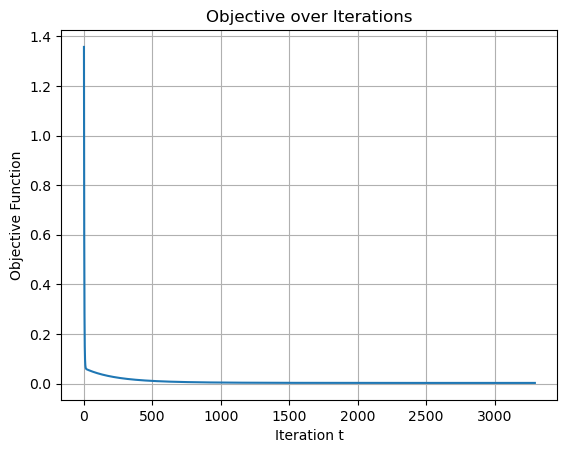

In [45]:
# Plotting the objective value against the iteration
iterations, values, _, _ = zip(*history)
plt.plot(iterations, values)
plt.xlabel('Iteration t')
plt.ylabel('Objective Function')
plt.title('Objective over Iterations')
plt.grid(True)
plt.show()